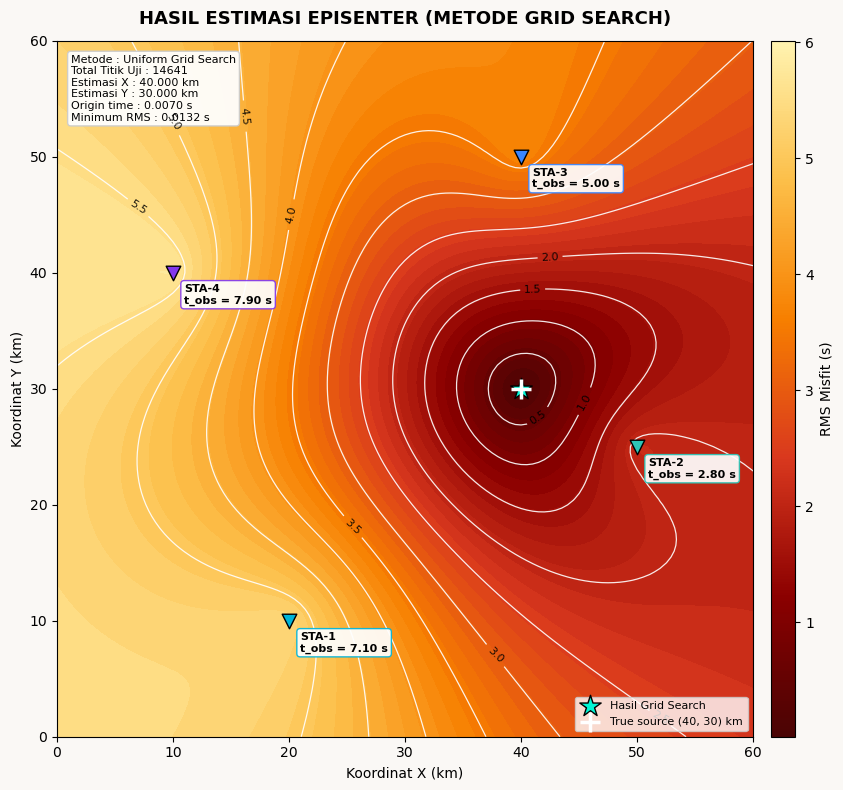

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from mpl_toolkits.axes_grid1 import make_axes_locatable

# 1. Data Pengamatan
XS = np.array([20.0, 50.0, 40.0, 10.0])
YS = np.array([10.0, 25.0, 50.0, 40.0])
T_OBS = np.array([7.1, 2.8, 5.0, 7.9])
STATION_NAMES = ["STA-1", "STA-2", "STA-3", "STA-4"]
N_STA = len(XS)
VP = 4.0  # km/s

# 2. Forward Model & Evaluasi RMS
def forward_model(x0, y0, t0, xs, ys, vp):
    distance = np.sqrt((xs - x0)**2 + (ys - y0)**2)
    t_cal = t0 + distance / vp
    return t_cal, distance

def evaluate_candidate(x0, y0):
    _, distance = forward_model(x0, y0, 0.0, XS, YS, VP)
    t0_est = np.mean(T_OBS - distance / VP)
    t_cal, _ = forward_model(x0, y0, t0_est, XS, YS, VP)
    residual = t_cal - T_OBS
    rms = np.sqrt(np.mean(residual**2))
    return rms, t0_est

# 3. Proses Grid Search Seragam
X_MIN, X_MAX = 0.0, 60.0
Y_MIN, Y_MAX = 0.0, 60.0
N_GRID = 121  # Resolusi grid seragam (121 x 121 titik = 14.641 titik)

x_vec = np.linspace(X_MIN, X_MAX, N_GRID)
y_vec = np.linspace(Y_MIN, Y_MAX, N_GRID)
XX, YY = np.meshgrid(x_vec, y_vec)

E_RMS_GRID = np.zeros_like(XX)
T0_GRID = np.zeros_like(XX)

for row in range(XX.shape[0]):
    for col in range(XX.shape[1]):
        E_RMS_GRID[row, col], T0_GRID[row, col] = evaluate_candidate(XX[row, col], YY[row, col])

# Cari indeks nilai RMS minimum di seluruh grid
min_idx = np.unravel_index(np.argmin(E_RMS_GRID), E_RMS_GRID.shape)
X_EST = XX[min_idx]
Y_EST = YY[min_idx]
T0_EST = T0_GRID[min_idx]
E_MIN = E_RMS_GRID[min_idx]

# 4. Visualisasi Grid Search
norm = Normalize(vmin=float(np.min(E_RMS_GRID)), vmax=float(np.min(E_RMS_GRID) + 6.0))
cmap = LinearSegmentedColormap.from_list(
    "maroon_to_yellow",
    ["#4A0404", "#8B0000", "#D9381E", "#F77F00", "#FCBF49", "#FFF3B0"]
)

fig, ax = plt.subplots(figsize=(10, 8), facecolor="#FAF8F5")
ax.set_facecolor("#FAF8F5")

ax.contourf(XX, YY, E_RMS_GRID, levels=40, cmap=cmap, norm=norm)
contours = ax.contour(
    XX, YY, E_RMS_GRID,
    levels=np.linspace(E_MIN, E_MIN + 5.5, 12),
    colors="#FFFFFF", linewidths=0.9, alpha=0.9
)
ax.clabel(contours, inline=True, fontsize=8, fmt="%.1f", colors="black")

# Stasiun & Episenter
station_colors = ["#00B4D8", "#2EC4B6", "#3A86FF", "#8338EC"]
for i in range(N_STA):
    ax.scatter(XS[i], YS[i], marker="v", s=110, color=station_colors[i], edgecolor="black", zorder=8)
    ax.annotate(
        f"{STATION_NAMES[i]}\nt_obs = {T_OBS[i]:.2f} s",
        (XS[i], YS[i]), xytext=(8, -22), textcoords="offset points",
        fontsize=8, weight="bold",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=station_colors[i], alpha=0.92),
        zorder=9
    )

ax.scatter(X_EST, Y_EST, marker="*", s=260, color="#00F5D4", edgecolor="black", zorder=12, label="Hasil Grid Search")
ax.scatter(40, 30, marker="+", s=220, linewidth=2.5, color="white", zorder=13, label="True source (40, 30) km")

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Koordinat X (km)")
ax.set_ylabel("Koordinat Y (km)")
ax.set_title("HASIL ESTIMASI EPISENTER (METODE GRID SEARCH)", fontsize=13, weight="bold", pad=12)
ax.legend(loc="lower right", facecolor="white", edgecolor="#CCCCCC", fontsize=8)

summary = (
    f"Metode : Uniform Grid Search\n"
    f"Total Titik Uji : {N_GRID * N_GRID}\n"
    f"Estimasi X : {X_EST:.3f} km\n"
    f"Estimasi Y : {Y_EST:.3f} km\n"
    f"Origin time : {T0_EST:.4f} s\n"
    f"Minimum RMS : {E_MIN:.4f} s"
)
ax.text(0.02, 0.98, summary, transform=ax.transAxes, va="top", ha="left", fontsize=8,
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="#CCCCCC", alpha=0.95))

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3.5%", pad=0.18)
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("RMS Misfit (s)")

plt.tight_layout()
plt.show()